<a href="https://colab.research.google.com/github/chughtaianosh-boop/evolvix-aiml-internship-anoshchughtai/blob/main/Week_3/week_3_task_1_Anosh.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Loading CIFAR-10 dataset...


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 4, 4, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │        65,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 122,570 (478.79 KB)

 Trainable params: 122,570 (478.79 KB)

 Non-trainable params: 0 (0.00 B)

Training the model for 12 epochs...
Epoch 1/12
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 77s 48ms/step - accuracy: 0.4549 - loss: 1.4963 - val_accuracy: 0.5675 - val_loss: 1.2041
Epoch 2/12
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 73s 46ms/step - accuracy: 0.5983 - loss: 1.1411 - val_accuracy: 0.6250 - val_loss: 1.0548
Epoch 3/12
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 73s 46ms/step - accuracy: 0.6482 - loss: 1.0011 - val_accuracy: 0.6425 - val_loss: 1.0094
Epoch 4/12
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 71s 46ms/step - accuracy: 0.6837 - loss: 0.9048 - val_accuracy: 0.6656 - val_loss: 0.9439
Epoch 5/12
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 71s 46ms/step - accuracy: 0.7101 - loss: 0.8275 - val_accuracy: 0.6878 - val_loss: 0.8823
Epoch 6/12
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 83s 46ms/step - accuracy: 0.7309 - loss: 0.7677 - val_accuracy: 0.6965 - val_loss: 0.8724
Epoch 7/12
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 72s 46ms/step - accuracy: 0.7490 - loss: 0.7128 - val_accuracy: 0.6925 - val_loss: 0.9058
Epoch 8/12
1563/1563 ━━━━━━━━━━━━━━━━━━━

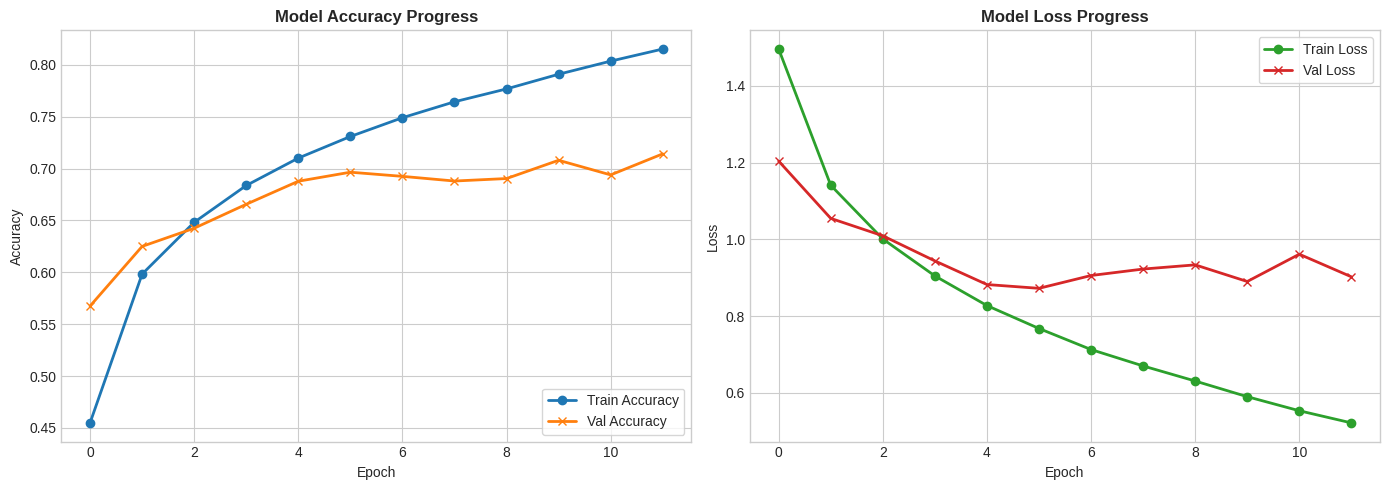

Running predictions on 5 sample test images...
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step


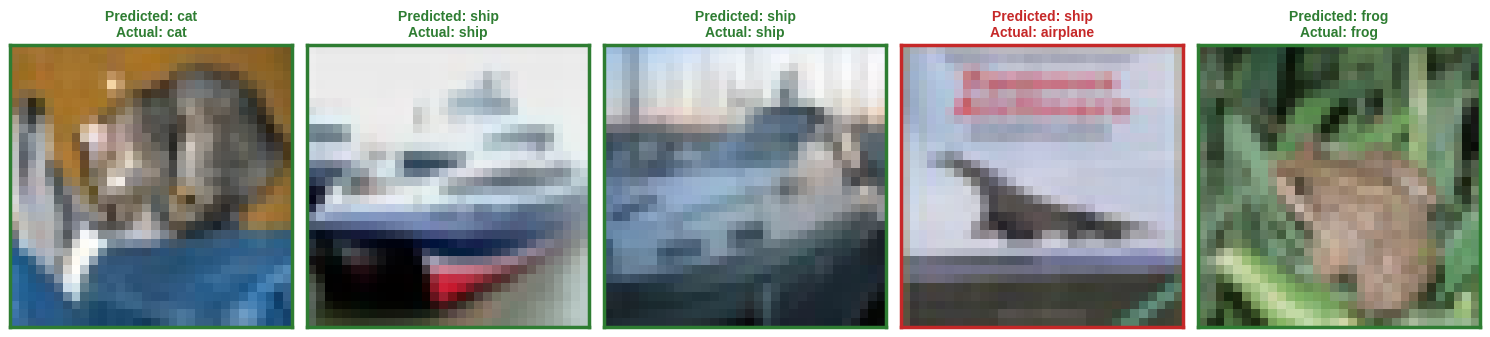

In [ ]:
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
import matplotlib.pyplot as plt
import numpy as np

# 1. Load and Preprocess the CIFAR-10 Dataset
print("Loading CIFAR-10 dataset...")
(train_images, train_labels), (test_images, test_labels) = datasets.cifar10.load_data()

# Normalize pixel values to be between 0 and 1
train_images, test_images = train_images / 255.0, test_images / 255.0

# Class names in the CIFAR-10 dataset
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

# 2. Build the CNN Model Architecture (Updated to avoid warnings)
model = models.Sequential([
    # Explicit Input layer instead of passing input_shape to Conv2D
    layers.Input(shape=(32, 32, 3)),

    # First Convolutional block
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Second Convolutional block
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Third Convolutional block
    layers.Conv2D(64, (3, 3), activation='relu'),

    # Flattening and Dense Layers
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10) # 10 output units for 10 classes
])

# Display the model summary
model.summary()

# 3. Compile the Model
model.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

# 4. Train the Model
epochs = 12
print(f"Training the model for {epochs} epochs...")
history = model.fit(train_images, train_labels, epochs=epochs,
                    validation_data=(test_images, test_labels))

# 5. Evaluate the Model
test_loss, test_acc = model.evaluate(test_images,  test_labels, verbose=2)
print(f"\nFinal Test Accuracy: {test_acc:.4f} ({test_acc * 100:.2f}%)")

# 6. Plot Training vs. Validation Evaluation Curves (Updated style)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot Accuracy
axes[0].plot(history.history['accuracy'], label='Train Accuracy', color='#1f77b4', linewidth=2, marker='o')
axes[0].plot(history.history['val_accuracy'], label='Val Accuracy', color='#ff7f0e', linewidth=2, marker='x')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].set_title('Model Accuracy Progress', fontsize=12, fontweight='bold')
axes[0].legend(loc='lower right', frameon=True)

# Plot Loss
axes[1].plot(history.history['loss'], label='Train Loss', color='#2ca02c', linewidth=2, marker='o')
axes[1].plot(history.history['val_loss'], label='Val Loss', color='#d62728', linewidth=2, marker='x')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].set_title('Model Loss Progress', fontsize=12, fontweight='bold')
axes[1].legend(loc='upper right', frameon=True)

plt.tight_layout()
plt.show()

# 7. Testing & Visualizing Predictions on 5 Sample Images (Refreshed layout)
print("Running predictions on 5 sample test images...")
probability_model = tf.keras.Sequential([model, tf.keras.layers.Softmax()])
predictions = probability_model.predict(test_images[:5])

fig, axes = plt.subplots(1, 5, figsize=(15, 4))
for i in range(5):
    axes[i].imshow(test_images[i])

    predicted_label = np.argmax(predictions[i])
    actual_label = test_labels[i][0]

    # Use a styled frame and background based on correctness
    is_correct = predicted_label == actual_label
    color = '#2e7d32' if is_correct else '#c62828' # Modern dark green and dark red

    axes[i].set_title(f"Predicted: {class_names[predicted_label]}\nActual: {class_names[actual_label]}",
                      color=color, fontsize=10, fontweight='bold')
    # Add a colored border around the subplot
    for spine in axes[i].spines.values():
        spine.set_edgecolor(color)
        spine.set_linewidth(2.5)
    axes[i].set_xticks([])
    axes[i].set_yticks([])

plt.tight_layout()
plt.show()